# Ecommerce Store: End-to-End Data Analysis Project

# 1. Setup

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio


pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

pio.renderers.default = 'png'
pio.renderers['png'].width = 850
pio.renderers['png'].height = 420


RANDOM_STATE = 42

# 2. Data Loading

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
import os
import mysql.connector

connec = mysql.connector.connect(
        host = os.getenv('MYSQL_HOST'),
        user = os.getenv('MYSQL_USER'),
        password = os.getenv('MYSQL_PASSWORD'),
        database = os.getenv('MYSQL_DATABASE')
)

TABLES = ['customers', 'orders', 'products', 'sales']
PK = {'customers': 'customer_id', 'orders': 'order_id', 'products': 'product_id', 'sales': 'sales_id'}


- 2.1) Load Tables

In [4]:
# Load `Customers`-table
query = 'SELECT * FROM customers'
customers = pd.read_sql(sql= query , con= connec)

# Load `Orders`-table
query = 'SELECT * FROM orders'
orders = pd.read_sql(sql= query , con= connec)

# Load `Products`-table
query = 'SELECT * FROM products'
products = pd.read_sql(sql= query , con= connec)

# Load `Sales`-table
query = 'SELECT * FROM sales'
sales = pd.read_sql(sql= query , con= connec)


display('_____ Customers _____', customers.head(1))
display('_____ Orders _____', orders.head(1))
display('_____ Products _____', products.head(1))
display('_____ Sales _____', sales.head(1))

C:\Users\cpu\AppData\Local\Temp\ipykernel_9188\1686723963.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  customers = pd.read_sql(sql= query , con= connec)
C:\Users\cpu\AppData\Local\Temp\ipykernel_9188\1686723963.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orders = pd.read_sql(sql= query , con= connec)
C:\Users\cpu\AppData\Local\Temp\ipykernel_9188\1686723963.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  products = pd.read_sql(sql= query , con= connec)
C:\Users\cpu\AppData\Local\Temp\ipykernel_9188\16867

'_____ Customers _____'

,customer_id,customer_name,gender,age,home_address,zip_code,city,state,country
0,1,Leanna Busson,Female,30,8606 Victoria TerraceSuite 560,5464,Johnstonhaven,Northern Territory,Australia


'_____ Orders _____'

,order_id,customer_id,order_date,delivery_date
0,1,64,2021-08-30,2021-09-24


'_____ Products _____'

,product_id,product_type,product_name,size,colour,quantity,description
0,0,Shirt,Oxford Cloth,XS,red,66,"A red coloured, XS sized, Oxford Cloth Shirt"


'_____ Sales _____'

,sales_id,order_id,product_id,price_per_unit,quantity,total_price
0,0,1,218,106.00,2,212.00


- 2.2) Merge Tabels

In [5]:
def merge_tables(customers, orders, sales, products):
# customers -> orders -> sales -> products
    return (customers
            .merge(orders,   on='customer_id', how='inner')
            .merge(sales,    on='order_id',    how='inner')
            .merge(products, on='product_id',  how='inner')
)
df = merge_tables(customers, orders, sales, products)
df.head(1)

,customer_id,customer_name,gender,age,home_address,zip_code,city,state,country,order_id,order_date,delivery_date,sales_id,product_id,price_per_unit,quantity_x,total_price,product_type,product_name,size,colour,quantity_y,description
0,1,Leanna Busson,Female,30,8606 Victoria TerraceSuite 560,5464,Johnstonhaven,Northern Territory,Australia,455,2021-04-04,2021-04-06,2245,211,106.00,3,318.00,Shirt,Chambray,S,red,72,"A red coloured, S sized, Chambray Shirt"


    - Cols: `quantity_x` & `quantity_y`      ~~>>   rename

In [6]:
df = df.rename(columns= {'quantity_x' : 'quantity', 'quantity_y' : 'stock'})
df.head(1)

,customer_id,customer_name,gender,age,home_address,zip_code,city,state,country,order_id,order_date,delivery_date,sales_id,product_id,price_per_unit,quantity,total_price,product_type,product_name,size,colour,stock,description
0,1,Leanna Busson,Female,30,8606 Victoria TerraceSuite 560,5464,Johnstonhaven,Northern Territory,Australia,455,2021-04-04,2021-04-06,2245,211,106.00,3,318.00,Shirt,Chambray,S,red,72,"A red coloured, S sized, Chambray Shirt"


# 3. Data Understanding

- Dataset: E-commerce Shopping store Sales Report

| Column | Description |
|--------|-------------|
| `customer_id` | Unique ID of the customer |
| `customer_name` | Full name of the customer |
| `gender` | Customer gender (e.g., Female, Male, Non-binary, Genderfluid) |
| `age` | Customer age in years |
| `home_address` | Customer street address |
| `zip_code` | Postal code of the customer |
| `city` | City of the customer |
| `state` | Australian state or territory of the customer |
| `country` | Country of the customer (always Australia) |
| `order_id` | Unique ID of the order (one order can have several rows) |
| `order_date` | Date the order was placed |
| `delivery_date` | Date the order was delivered |
| `sales_id` | Unique ID of each sales line item (row) |
| `product_id` | Unique ID of the product variant |
| `price_per_unit` | Price of one unit of the product |
| `quantity` | Number of units purchased (1 to 3) |
| `total_price` | Total line amount (`price_per_unit` × `quantity`) |
| `product_type` | Product category (Shirt, Jacket, Trousers) |
| `product_name` | Product style (e.g., Chambray, Leather) |
| `size` | Product size (XS, S, M, L, XL) |
| `colour` | Product colour (e.g., red, blue, green) |
| `stock` | Stock level available for the product |
| `description` | Auto-generated text from colour, size, name and type |

# 4. Data Exploration

In [7]:
print(f'Shape: {df.shape}\n')

Shape: (5000, 23)



 - 4.1) Check Data Types

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     5000 non-null   int64  
 1   customer_name   5000 non-null   object 
 2   gender          5000 non-null   object 
 3   age             5000 non-null   int64  
 4   home_address    5000 non-null   object 
 5   zip_code        5000 non-null   object 
 6   city            5000 non-null   object 
 7   state           5000 non-null   object 
 8   country         5000 non-null   object 
 9   order_id        5000 non-null   int64  
 10  order_date      5000 non-null   object 
 11  delivery_date   5000 non-null   object 
 12  sales_id        5000 non-null   int64  
 13  product_id      5000 non-null   int64  
 14  price_per_unit  5000 non-null   float64
 15  quantity        5000 non-null   int64  
 16  total_price     5000 non-null   float64
 17  product_type    5000 non-null   o

    - Cols: `order_date`, `delivery_date`         ~~>>         object not datetime64
    - Cols: `home_address`, `zip_code`, `country`,`description`     ~~>>     not need for analysis

- 4.2) Check Duplicates

In [9]:
print('Duplicate rows :', df.duplicated().sum())
print('Duplicate sales_id  :', df['sales_id'].duplicated().sum())

Duplicate rows : 0
Duplicate sales_id  : 0


- 4.3) Check Summary Statistics

In [10]:
# Numerical columns
df.describe(include= 'number')

,customer_id,age,order_id,sales_id,product_id,price_per_unit,quantity,total_price,stock
count,"5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00"
mean,504.56,48.76,503.04,"2,499.50",634.05,103.50,1.99,206.36,60.08
std,276.50,17.58,285.96,"1,443.52",363.26,9.20,0.81,86.36,11.68
min,1.00,20.00,1.00,0.00,1.00,90.00,1.00,90.00,40.00
25%,276.00,34.00,258.00,"1,249.75",323.00,95.00,1.00,112.00,50.00
50%,509.00,48.00,504.50,"2,499.50",635.00,102.00,2.00,204.00,60.00
75%,733.00,63.00,749.00,"3,749.25",951.00,112.00,3.00,285.00,70.00
max,"1,000.00",80.00,999.00,"4,999.00","1,259.00",119.00,3.00,357.00,80.00


- Depth check for `Numerical` columns

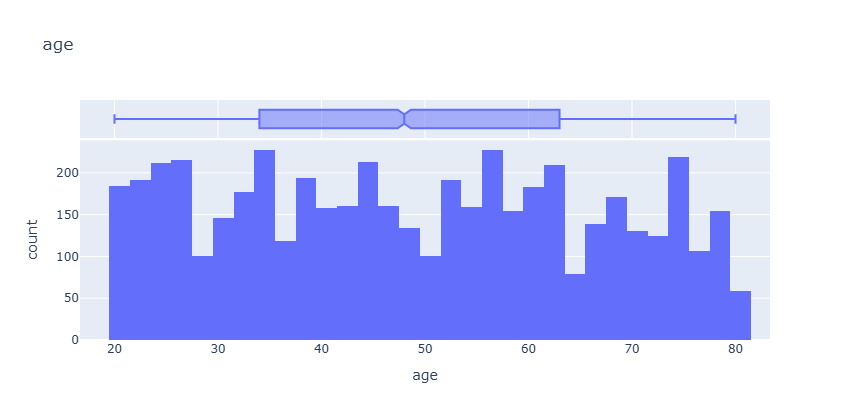

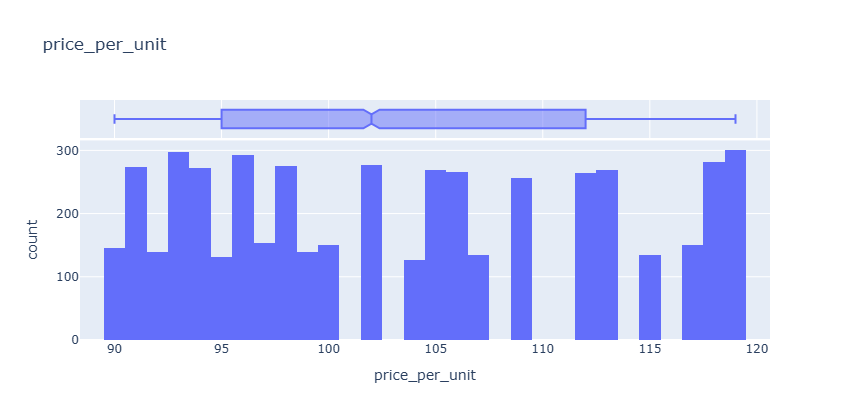

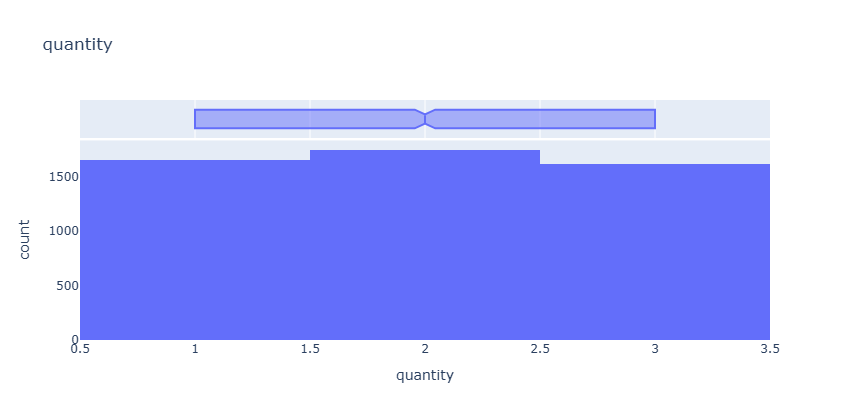

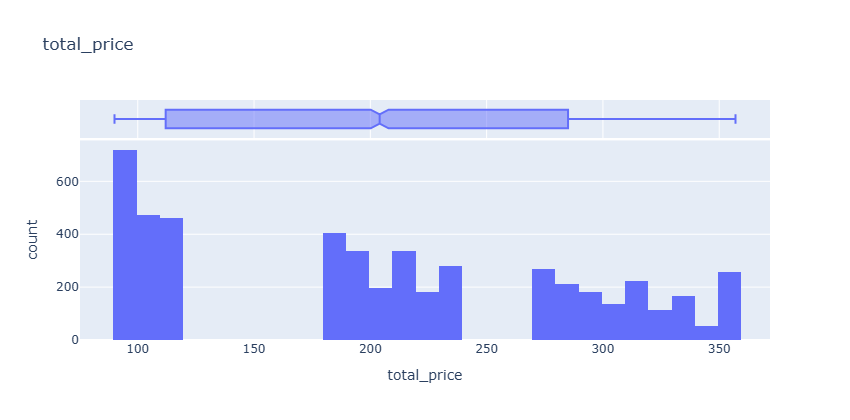

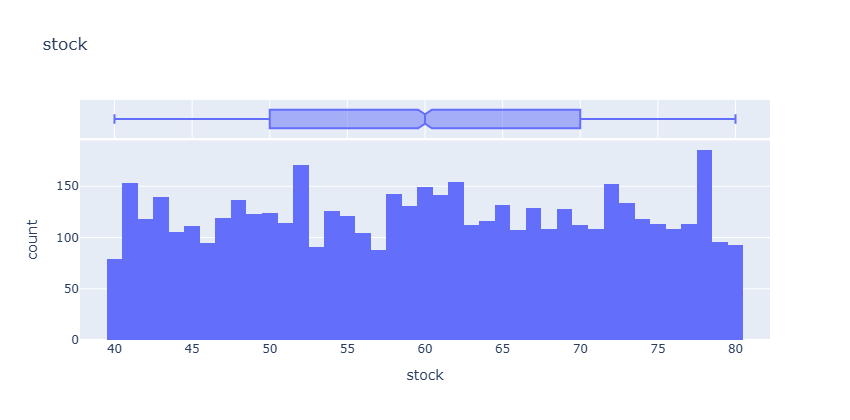

In [11]:
numc_cols = df.select_dtypes(include= 'number').columns.drop(['customer_id', 'order_id', 'sales_id', 'product_id'])

for col in numc_cols:
    px.histogram(data_frame= df, x= col, title= col, marginal='box').show()

In [12]:
# Categorical columns
df.describe(include='object')

,customer_name,gender,home_address,zip_code,city,state,country,order_date,delivery_date,product_type,product_name,size,colour,description
count,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
unique,616,8,616,603,604,8,1,291,304,3,35,5,7,1233
top,Kristofor Roos,Female,5567 Clarke MallApt. 756,4043,Jordanside,South Australia,Australia,2021-06-21,2021-03-28,Trousers,Denim,M,blue,"A orange coloured, L sized, Flannel Shirt"
freq,37,712,37,37,37,718,5000,51,49,1683,273,1022,762,13


- Depth check for Categorical columns

In [13]:
catg_cols = df.select_dtypes(include= 'object')

for col in catg_cols:
    print(f'_____', col, '______')
    print(df[col].nunique())
    print(df[col].unique())
    print('\n', '-' * 100, '\n')

_____ customer_name ______
616
['Leanna Busson' 'Winslow Ewbanck' 'Susanetta Wilshin'
 'Michaeline McIndrew' 'Fedora Dmych' 'Marabel Swinfon' 'Avril Rossiter'
 'Gabbie Aldwinckle' 'Chan Duchesne' 'Chadwick Cruddas' 'Gigi Kalaher'
 'Seana Hearons' 'Blayne Sabatier' 'Alair Grimwad' 'Ernaline Luce'
 'Timothy Compston' 'Jayme Turvie' 'Hadley Baddam' 'Ninon Corteney'
 'Adamo Saddington' 'Regan Gronaller' 'Hana Stitch' 'Horatius Genever'
 'Avivah Chipchase' 'Vicki Stockwell' 'Meris Twitty' 'Jarrett Brumby'
 'Shanna Pietrzyk' 'Moore Oolahan' 'Kayley Brosoli' 'Marena Lockhart'
 'Tore Caras' 'Giles Kyne' 'Aurie Margett' 'Hyacinth Pepper' 'Lin Avraam'
 'Denice Ledrane' 'Annabella Devote' 'Willa Gaisford' 'Tiphany Peacop'
 'Dulcea Shrawley' 'Marinna Heal' 'Jehanna Water' 'Katinka Currier'
 'Chandra Carine' 'Angela Kester' 'Jethro Pollak' 'Persis Spiteri'
 'Lanny Wardale' 'Kayne Fraczkiewicz' 'Minta Loble' 'Cornie Virr'
 'Corinna Maystone' 'Barbara-anne Salerg' 'Kendall Jakubski'
 'Matthiew Hincke

- 4.4) Check Missing Values

In [14]:
missing_values = pd.DataFrame({
    'count': df.isna().sum(),
    'percentage': (df.isna().mean() * 100),
})
missing_values[missing_values['count'] > 0].sort_values('count', ascending=False)

,count,percentage


# 5.) Data Cleaning

- 5.1) Drop cols: `home_address`, `zip_code`, `country`,`description`

In [15]:
df.drop(['home_address', 'zip_code', 'country', 'description'], axis= 1, inplace= True)

display(f'Shape:', df.shape)
df.head(1)

'Shape:'

(5000, 19)

,customer_id,customer_name,gender,age,city,state,order_id,order_date,delivery_date,sales_id,product_id,price_per_unit,quantity,total_price,product_type,product_name,size,colour,stock
0,1,Leanna Busson,Female,30,Johnstonhaven,Northern Territory,455,2021-04-04,2021-04-06,2245,211,106.00,3,318.00,Shirt,Chambray,S,red,72


- 5.2) Convert cols: `order_date`, `delivery_date` to Datetime

In [16]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['delivery_date'] = pd.to_datetime(df['delivery_date'])

df.dtypes

customer_id                int64
customer_name             object
gender                    object
age                        int64
city                      object
state                     object
order_id                   int64
order_date        datetime64[ns]
delivery_date     datetime64[ns]
sales_id                   int64
product_id                 int64
price_per_unit           float64
quantity                   int64
total_price              float64
product_type              object
product_name              object
size                      object
colour                    object
stock                      int64
dtype: object

- 5.3) Title col `colour`

In [17]:
df['colour'] = df['colour'].str.title()
df.head(1)

,customer_id,customer_name,gender,age,city,state,order_id,order_date,delivery_date,sales_id,product_id,price_per_unit,quantity,total_price,product_type,product_name,size,colour,stock
0,1,Leanna Busson,Female,30,Johnstonhaven,Northern Territory,455,2021-04-04,2021-04-06,2245,211,106.00,3,318.00,Shirt,Chambray,S,Red,72


# 6. Feature Engineering

- 6.1) Time features

In [18]:
SIZE_ORDER = ['XS', 'S', 'M', 'L', 'XL']
WEEKDAY_ORDER = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
BINS = [19, 29, 39, 49, 59, 69, 120]
LABELS = ['20-29', '30-39', '40-49', '50-59', '60-69', '70+']


In [19]:
df['month'] = df['order_date'].dt.month
df['month_name'] = df['order_date'].dt.month_name()
df['day'] = df['order_date'].dt.day
df['weekday'] = df['order_date'].dt.day_name()
df['is_weekend'] = (df['order_date'].dt.dayofweek >= 5).astype(int)
df['week_start'] = df['order_date'].dt.to_period('W').dt.start_time
df.head(1)

,customer_id,customer_name,gender,age,city,state,order_id,order_date,delivery_date,sales_id,product_id,price_per_unit,quantity,total_price,product_type,product_name,size,colour,stock,month,month_name,day,weekday,is_weekend,week_start
0,1,Leanna Busson,Female,30,Johnstonhaven,Northern Territory,455,2021-04-04,2021-04-06,2245,211,106.00,3,318.00,Shirt,Chambray,S,Red,72,4,April,4,Sunday,1,2021-03-29


- 6.2) Delivery time

In [20]:
df['delivery_days'] = (df['delivery_date'] - df['order_date']).dt.days
df.head(1)

,customer_id,customer_name,gender,age,city,state,order_id,order_date,delivery_date,sales_id,product_id,price_per_unit,quantity,total_price,product_type,product_name,size,colour,stock,month,month_name,day,weekday,is_weekend,week_start,delivery_days
0,1,Leanna Busson,Female,30,Johnstonhaven,Northern Territory,455,2021-04-04,2021-04-06,2245,211,106.00,3,318.00,Shirt,Chambray,S,Red,72,4,April,4,Sunday,1,2021-03-29,2


- 6.3) Age group

In [21]:
df['age_group'] = pd.cut(df['age'], bins= BINS,
                         labels= LABELS)
print('Final shape:', df.shape)
df['age_group'].value_counts().sort_index()

Final shape: (5000, 27)


age_group
20-29    903
30-39    862
40-49    826
50-59    832
60-69    782
70+      795
Name: count, dtype: int64

In [22]:
print('Final shape:', df.shape)

Final shape: (5000, 27)


# 7. Data Analysis

- 7.1) How many customers per state ?

                          state  customer_id
0                      Tasmania           67
1  Australian Capital Territory           73
2            Northern Territory           75
3                      Victoria           75
4               New South Wales           77
5                    Queensland           79
6             Western Australia           80
7               South Australia           90


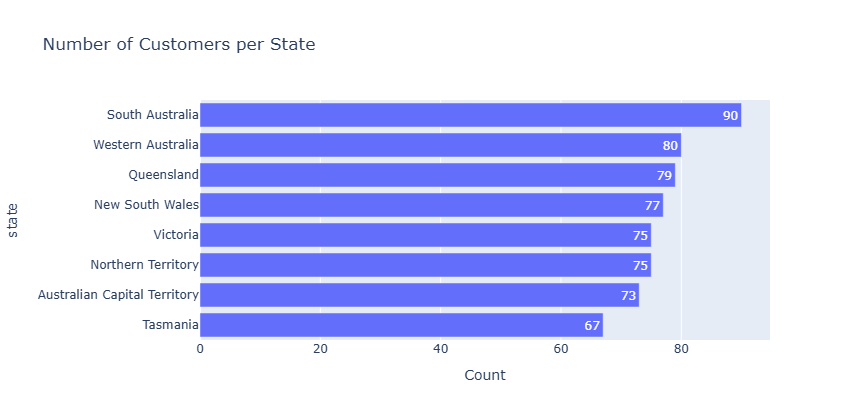

In [23]:
plot_df = df.groupby('state')['customer_id'].nunique().sort_values().reset_index()
print(plot_df)

px.bar(data_frame= plot_df, y= 'state', x= 'customer_id', text_auto= True,
       labels= {'customer_id' : 'Count'},
       title= 'Number of Customers per State')

- 7.2) How are sales trending?

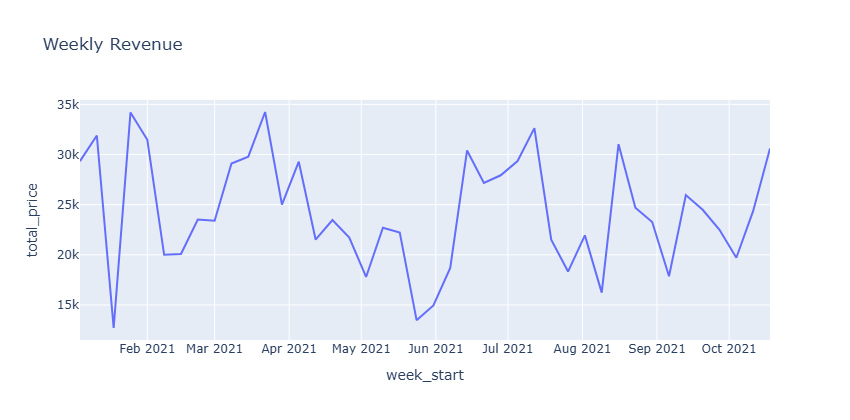

In [24]:
weekly = df.groupby('week_start')['total_price'].sum().reset_index().iloc[1:]
px.line(weekly, x='week_start', y='total_price', title='Weekly Revenue')

- October only runs until the 24th, so comparing monthly totals would be unfair.
- Revenue is divided by the number of days each month is covered.

         revenue  days  avg_daily_revenue
month                                    
1     119,333.00    31           3,849.00
2      95,080.00    28           3,396.00
3     131,364.00    31           4,238.00
4      97,530.00    30           3,251.00
5      85,597.00    31           2,761.00
6     101,458.00    30           3,382.00
7     116,081.00    31           3,745.00
8     104,565.00    31           3,373.00
9      96,526.00    30           3,218.00
10     84,266.00    24           3,511.00


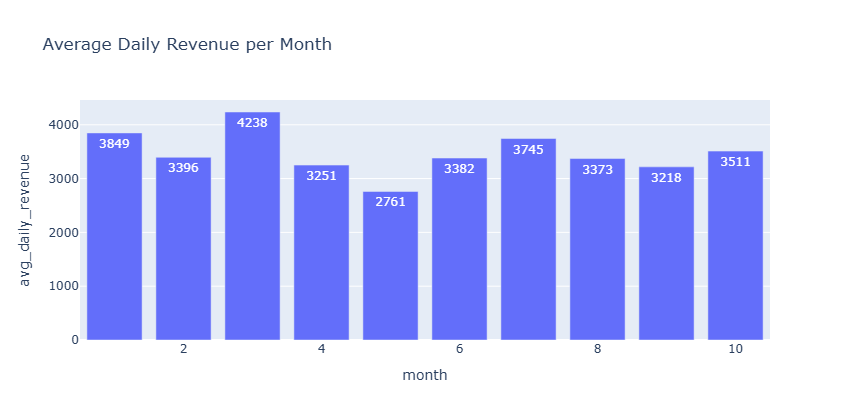

In [25]:
calendar = pd.Series(pd.date_range(df['order_date'].min(), df['order_date'].max())).dt.month.value_counts()

monthly = df.groupby('month')['total_price'].sum().to_frame('revenue')
monthly['days'] = calendar
monthly['avg_daily_revenue'] = (monthly['revenue'] / monthly['days']).round(0)
print(monthly)

px.bar(monthly.reset_index(), x='month', y='avg_daily_revenue', text_auto=True, title='Average Daily Revenue per Month')

- 7.3) What sells best?

  product_type  total_price
0       Jacket   357,026.00
1     Trousers   341,174.00
2        Shirt   333,600.00


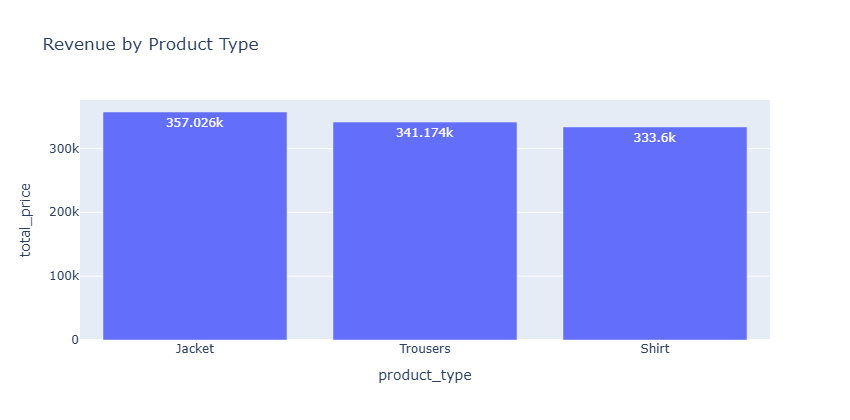

In [26]:
by_type = df.groupby('product_type')['total_price'].sum().sort_values(ascending=False).reset_index()
print(by_type)

px.bar(by_type, x='product_type', y='total_price', text_auto=True, title='Revenue by Product Type')

  product_type     product_name  total_price                  product
0        Shirt  Casual Slim Fit    36,414.00  Shirt - Casual Slim Fit
1       Jacket      Trench Coat    35,581.00     Jacket - Trench Coat
2       Jacket        Shearling    35,334.00       Jacket - Shearling
3       Jacket           Puffer    35,164.00          Jacket - Puffer
4        Shirt          Flannel    33,158.00          Shirt - Flannel
5     Trousers          Cropped    32,660.00       Trousers - Cropped
6     Trousers          Pleated    32,340.00       Trousers - Pleated
7     Trousers          Joggers    31,062.00       Trousers - Joggers
8        Shirt         Chambray    30,740.00         Shirt - Chambray
9       Jacket            Parka    30,397.00           Jacket - Parka


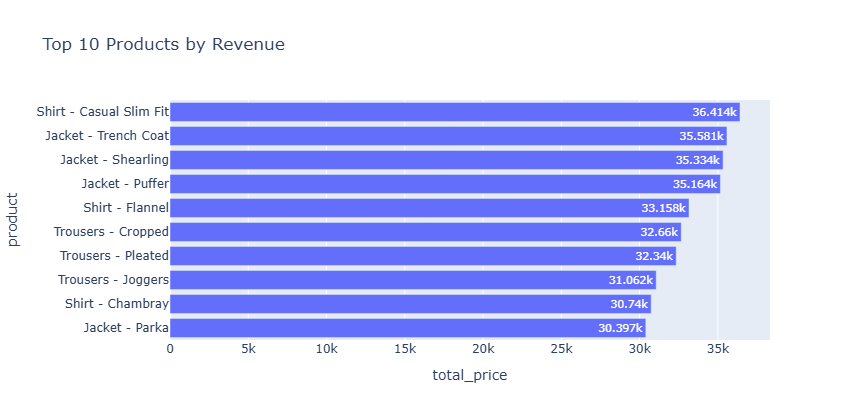

In [27]:
top_products = (df.groupby(['product_type', 'product_name'])['total_price'].sum()
                  .sort_values(ascending=False).head(10).reset_index())
top_products['product'] = top_products['product_type'] + ' - ' + top_products['product_name']
print(top_products)

px.bar(top_products.sort_values('total_price'), y='product', x='total_price', text_auto=True, title='Top 10 Products by Revenue')

- Size and colour, measured.

  size  quantity
0   XS      1990
1    S      1992
2    M      2036
3    L      1998
4   XL      1946


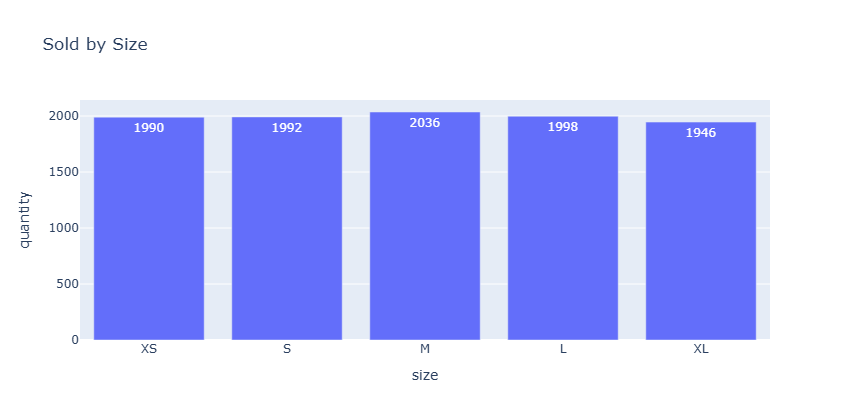

In [28]:
by_size = df.groupby('size')['quantity'].sum().reindex(SIZE_ORDER).reset_index()
print(by_size)

px.bar(by_size, x='size', y='quantity', text_auto=True, title='Sold by Size')

   colour  quantity
0    Blue      1528
1  Violet      1448
2  Indigo      1445
3     Red      1407
4  Yellow      1389
5   Green      1386
6  Orange      1359


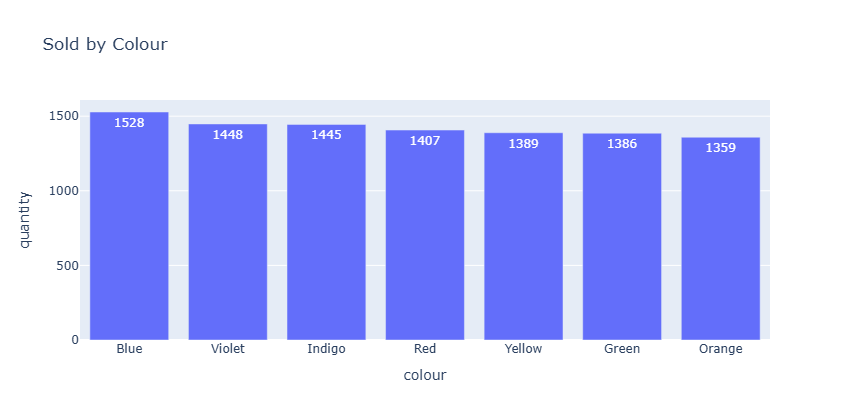

In [29]:
by_colour = df.groupby('colour')['quantity'].sum().sort_values(ascending=False).reset_index()
print(by_colour)

px.bar(by_colour, x='colour', y='quantity', text_auto=True, title='Sold by Colour')

- 7.4) Who buys?

             revenue  customers  revenue_per_customer
age_group                                            
20-29     182,852.00        107              1,709.00
30-39     178,025.00         97              1,835.00
40-49     166,731.00        105              1,588.00
50-59     177,811.00        105              1,693.00
60-69     159,680.00        102              1,565.00
70+       166,701.00        100              1,667.00


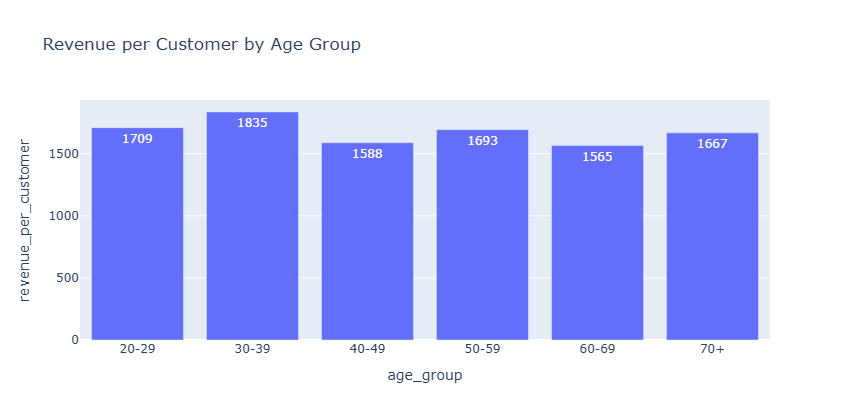

In [30]:
by_age = df.groupby('age_group', observed=True).agg(revenue=('total_price', 'sum'), customers=('customer_id', 'nunique'))
by_age['revenue_per_customer'] = (by_age['revenue'] / by_age['customers']).round(0)
print(by_age)

px.bar(by_age.reset_index(), x='age_group', y='revenue_per_customer', text_auto=True, title='Revenue per Customer by Age Group')

               revenue  customers  revenue_per_customer
gender                                                 
Female      145,404.00         73              1,991.84
Non-binary  126,201.00         72              1,752.79
Polygender  132,548.00         78              1,699.33
Male        138,988.00         82              1,694.98
Genderqueer 132,389.00         79              1,675.81
Genderfluid 142,077.00         87              1,633.07
Bigender    107,014.00         69              1,550.93
Agender     107,179.00         76              1,410.25


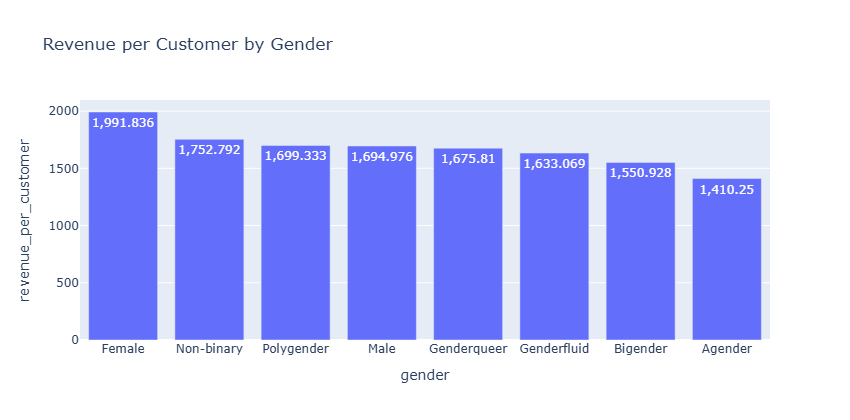

In [31]:
by_gender = df.groupby('gender').agg(revenue=('total_price', 'sum'), customers=('customer_id', 'nunique'))
by_gender['revenue_per_customer'] = (by_gender['revenue'] / by_gender['customers'])
by_gender = by_gender.sort_values('revenue_per_customer', ascending=False)
print(by_gender)

px.bar(by_gender.reset_index(), x='gender', y='revenue_per_customer', text_auto=True, title='Revenue per Customer by Gender')

- 7.5) When customers buy?

Days with no sales: 6
     weekday  avg_daily_revenue
0     Monday           3,230.76
1    Tuesday           3,653.40
2  Wednesday           3,625.05
3   Thursday           3,310.98
4     Friday           3,102.65
5   Saturday           3,242.00
6     Sunday           4,151.91


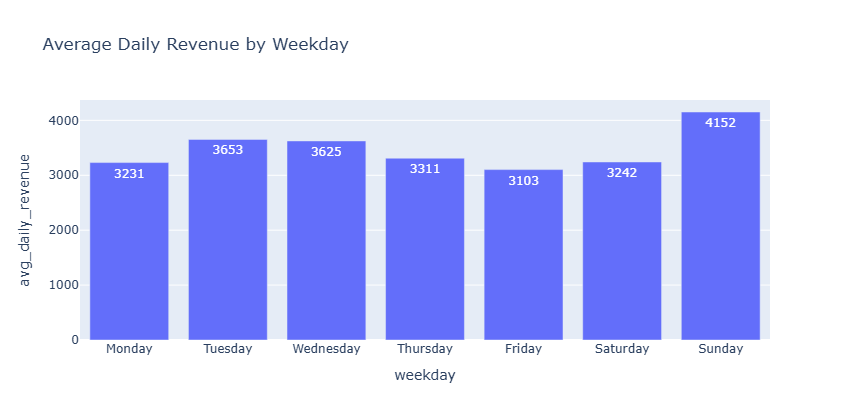

In [32]:
daily = df.groupby('order_date')['total_price'].sum()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)
print('Days with no sales:', (daily == 0).sum())

by_weekday = daily.groupby(daily.index.day_name()).mean().reindex(WEEKDAY_ORDER).reset_index()
by_weekday.columns = ['weekday', 'avg_daily_revenue']
print(by_weekday)

px.bar(by_weekday, x='weekday', y='avg_daily_revenue', text_auto='.0f', title='Average Daily Revenue by Weekday')

- 7.6) How long delivery take?

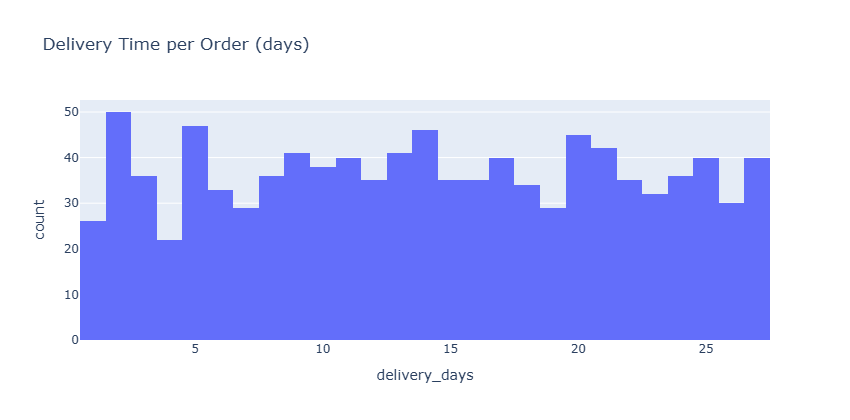

In [33]:
orders_df = df.drop_duplicates('order_id')

px.histogram(orders_df, x='delivery_days', title='Delivery Time per Order (days)')

                          state  delivery_days
0                    Queensland          13.20
1            Northern Territory          13.50
2  Australian Capital Territory          13.90
3             Western Australia          13.90
4                      Tasmania          14.00
5                      Victoria          14.30
6               South Australia          14.80
7               New South Wales          14.80


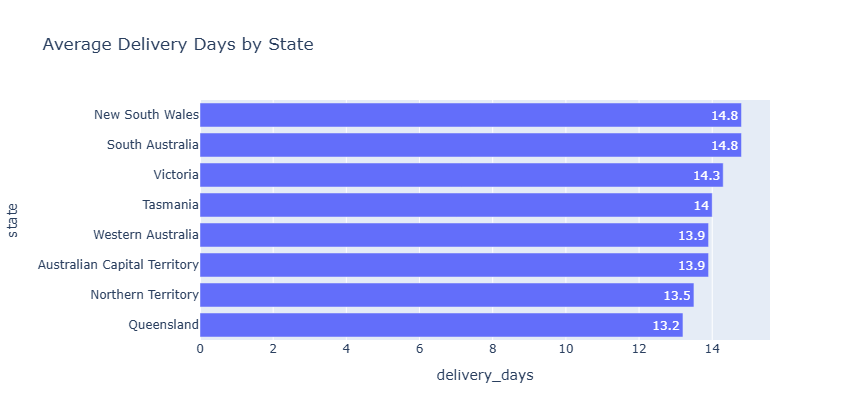

In [34]:
by_state = orders_df.groupby('state')['delivery_days'].mean().sort_values().round(1).reset_index()
print(by_state)

px.bar(by_state, y='state', x='delivery_days', text_auto=True, title='Average Delivery Days by State')